In [ ]:
# Importa las librerias y dependencias del notebook.

import matplotlib.pyplot as plt
from datos import obtener_vix

Datos del VIX descargados en 1.91 segundos.
Temporalidad 60m: (598, 5)
Temporalidad 1d: (44, 5)
Temporalidad 7d: (53, 5)


Price,Close,High,Low,Open,Volume
Ticker,^VIX,^VIX,^VIX,^VIX,^VIX
Date,,,,,
2026-10-20,17.309999,19.129999,17.250000,18.420000,0
2026-10-21,16.680000,17.580000,16.510000,17.250000,0
2026-10-22,19.030001,20.309999,17.709999,18.290001,0
2026-10-23,19.450001,20.660000,18.870001,19.180000,0
2026-10-26,18.340000,19.840000,17.790001,19.660000,0


Datos del VIX descargados en 2.63 segundos.


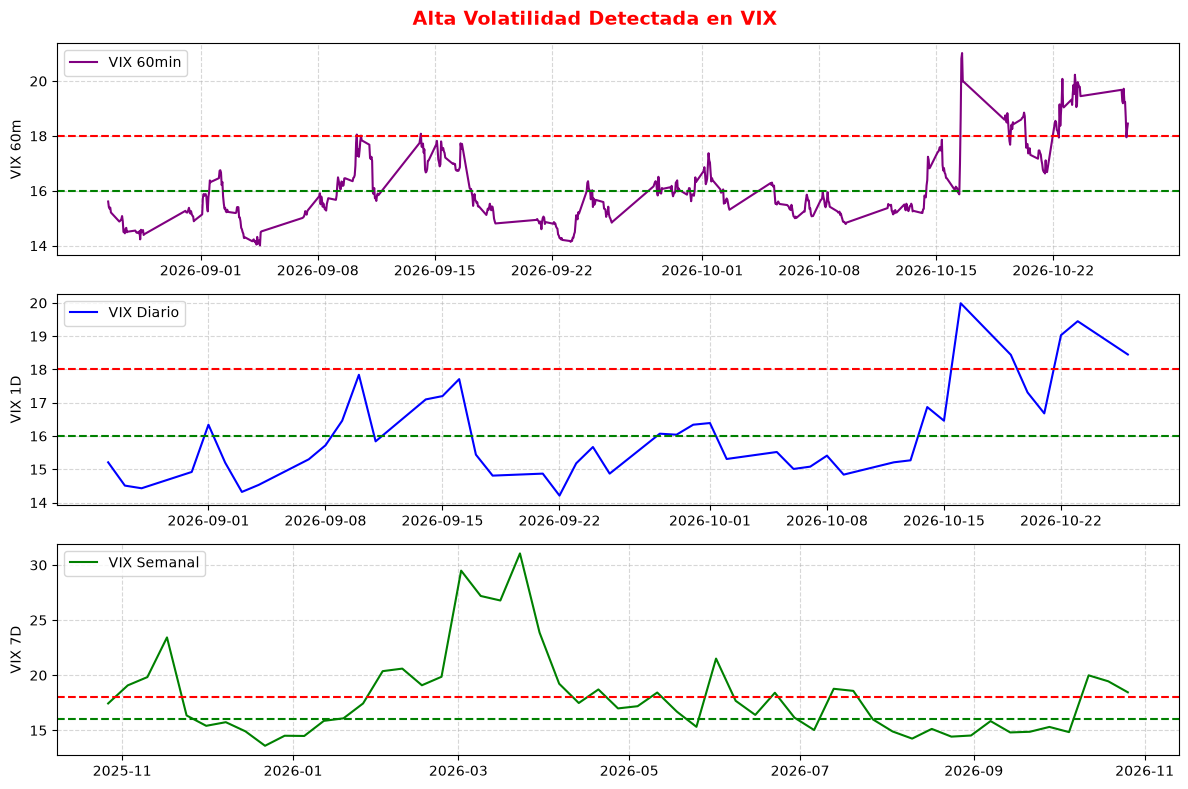

In [6]:
# Índice de volatilidad VIX.

volatilidad = False
vix_60m, vix_1d, vix_7d = obtener_vix()

if (vix_60m['High'].iloc[-1].item() > 18) or (vix_60m['High'].iloc[-1].item()>vix_60m['High'].iloc[0].item()):
    volatilidad = True

# Grafica en las 3 temporalidades.
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 8))

if volatilidad:
  fig.suptitle(
      'Alta Volatilidad Detectada en VIX',
      fontsize=14,
      color='red',
      fontweight='bold',
  )
else:
  fig.suptitle(
      'Monitoreo del Índice de Volatilidad VIX', fontsize=14, color='black'
  )

ax1.plot(vix_60m.index, vix_60m['Close'], label='VIX 60min', color='purple')
ax1.set_ylabel('VIX 60m')
ax1.legend(loc='upper left')

ax2.plot(vix_1d.index, vix_1d['Close'], label='VIX Diario', color='blue')
ax2.set_ylabel('VIX 1D')
ax2.legend(loc='upper left')

ax3.plot(vix_7d.index, vix_7d['Close'], label='VIX Semanal', color='green')
ax3.set_ylabel('VIX 7D')
ax3.legend(loc='upper left')

plt.tight_layout()

for ax in (ax1, ax2, ax3):
    ax.axhline(y=16, color='green', linestyle='--', label='Umbral 16')# Normal
    ax.axhline(y=18, color='red', linestyle='--', label='Umbral 18') # Risk
    ax.grid(True, linestyle="--", alpha=0.5)
    

plt.show()